# EquiTech — diagnostic des rémunérations

**Simulation pédagogique : données synthétiques.**

Le fichier contient 12 000 salariés synthétiques, des temps contractuels différents, des niveaux de poste, métiers et sites. Des quotités sont impossibles, certaines rémunérations sont négatives et un micro-site crée des petits groupes. Les données sont fictives ; le cas réel demanderait une gouvernance distincte.

## Objectif et démarche

Expliquer l’écart salarial observé, séparer composition des postes et association ajustée, puis construire une restitution agrégée maîtrisant les risques de diffusion.

- Les salaires sont-ils comparables avant normalisation ? Comment définir une rémunération annuelle équivalent temps plein ?
- Quel écart brut observe-t-on avec intervalle d’incertitude ? Comment médiane, moyenne et composition des niveaux diffèrent-elles ?
- Quel écart ajusté descriptif obtient-on en contrôlant niveau, métier, site, âge et ancienneté ? Quelles limites subsistent ?
- Quels groupes doivent être masqués et comment les totaux ou croisements pourraient-ils malgré tout révéler un petit groupe ?
- Quelles vérifications complémentaires recommander sans transformer une régression en preuve de discrimination ni en index légal ?

Exécuter les cellules dans l’ordre. Les sources synthétiques sont régénérées avec une graine fixe ; les données réelles éventuelles nécessiteraient une étape de chargement distincte.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


## Fonctions de qualité et de visualisation

Ces fonctions centralisent les exports CSV, la traçabilité des exclusions et les légendes des graphiques. Le bilan brut = doublons + rejets + propre est vérifié par assertion.

In [2]:
DEFAULT_UNITS = {'region': 'Région fictive', 'nom': 'Nom fictif', 'population': 'personnes', 'surface': 'm²', 'pieces': 'nombre de pièces', 'type': 'type de bien', 'date': 'ISO yyyy-MM-dd', 'prix': 'EUR/unité (transaction : EUR/bien)', 'nature': 'principal/annexe', 'categorie': 'catégorie produit', 'annee': 'année civile', 'kcal_kg': 'kcal/kg', 'production_t': 'tonnes/an', 'importations_t': 'tonnes/an', 'exportations_t': 'tonnes/an', 'variation_stock_t': 'tonnes/an, signe positif = apport au bilan', 'pertes_t': 'tonnes/an', 'alimentation_animale_t': 'tonnes/an', 'autres_usages_t': 'tonnes/an', 'cout': 'EUR/unité', 'stock_initial': 'unités, proxy de stock moyen', 'sku': 'identifiant web fictif', 'quantite': 'unités', 'remise': 'fraction, 0.10 = 10 %', 'retour': 'unités retournées', 'age': 'années', 'anciennete': 'années', 'segment': 'particulier/professionnel fictif', 'sexe': 'F/H, catégories simplifiées de la simulation', 'niveau': 'niveau de poste fictif', 'metier': 'famille métier fictive', 'site': 'site fictif', 'quotite': 'ETP contractuel, 0 < x <= 1', 'salaire_annuel_verse': 'EUR/an au temps contractuel', 'pays': 'territoire fictif', 'zone': 'Rural/Urbain', 'acces_sur_pct': 'pourcentage 0–100', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne', 'pib_habitant': 'USD fictifs/personne/an', 'conso_kg_hab': 'kg/personne/an', 'risque_logistique': 'score 0–100, élevé défavorable', 'croissance_pct': 'points de pourcentage annuel', 'est_faux': '1=faux simulé, 0=authentique simulé', 'diagonale': 'mm', 'hauteur_gauche': 'mm', 'hauteur_droite': 'mm', 'marge_haute': 'mm', 'marge_basse': 'mm', 'longueur': 'mm'}

def csv(df, file):
    df.to_csv(file, index=False, sep=';', encoding='utf-8-sig', float_format='%.8f')

def source(df, name, grain, units=None):
    csv(df, RAW / (name + '.csv'))
    for c in df:
        DICT.append({'table': name, 'grain': grain, 'colonne': c, 'type': str(df[c].dtype), 'unite_ou_sens': (units or {}).get(c, DEFAULT_UNITS.get(c, 'Identifiant fictif' if c.endswith('_id') else 'Voir énoncé et code de génération')), 'manquants': int(df[c].isna().sum())})

def clean(df, key, mask, name):
    dup = df.duplicated(key, keep='first')
    u = df.loc[~dup].copy()
    valid = mask(u).fillna(False)
    rejects = u.loc[~valid].copy()
    rejects['motif'] = 'Contrat de validation violé : voir les cellules de nettoyage du notebook'
    csv(df.loc[dup], OUT / (name + '_doublons.csv'))
    csv(rejects, OUT / (name + '_rejets.csv'))
    r = u.loc[valid].copy()
    AUDIT.append({'table': name, 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': len(rejects), 'propre': len(r)})
    csv(r, CLEAN / (name + '.csv'))
    assert len(df) == int(dup.sum()) + len(rejects) + len(r)
    assert not r.duplicated(key).any()
    return r

FIGURE_LABELS = {'flux_stations': ('Solde des flux par station', 'Identifiant de station', 'Arrivées moins départs, locations'), 'ca_maintenance': ('Recettes et maintenance mensuelles', 'Mois', 'EUR'), 'prix_m2_annuel': ('Prix au m² — territoires fictifs', 'Année', 'Médiane des médianes communales, EUR/m²'), 'erreurs_prediction': ('Erreurs du modèle sur 2025', 'Prédiction moins prix réel, EUR', 'Nombre de ventes'), 'disponibilite_ponderee': ('Disponibilité calorique — bilans complets', 'Année', 'kcal/jour/personne, pondéré par population'), 'dependance_et_disponibilite': ('Dépendance aux importations et disponibilité', 'Importations / (production + importations)', 'Disponibilité, kcal/jour/personne'), 'distribution_prix': ('Distribution des prix catalogue', 'Logarithme naturel du prix en EUR', 'Nombre de références'), 'pareto_ca': ('Concentration du chiffre d’affaires', 'Fraction des références, par CA décroissant', 'Fraction cumulée du CA'), 'ca_et_marge_mensuels': ('Ventes et marge commerciale', 'Mois', 'EUR'), 'decomposition': ('Série mensuelle et décomposition STL', 'Mois', 'EUR'), 'validation_prevision': ('Prévision — six mois de test chronologique', 'Mois', 'Chiffre d’affaires net, EUR'), 'retention_cohortes': ('Rétention par cohorte — cellules futures non observées', 'Ancienneté en mois', 'Cohorte, ordre chronologique'), 'salaires_etp': ('Distribution des salaires normalisés ETP', 'Catégorie de sexe simulée', 'EUR/an équivalent temps plein'), 'ecarts_brut_ajuste': ('Écart salarial descriptif', 'Méthode', 'Écart en %, référence masculine'), 'besoin_regional': ('Population sans accès — données observées', 'Année', '% de la population observée'), 'stabilite_priorites': ('Sensibilité des priorités à la pondération', 'Identifiant du territoire fictif', 'Rang (1 = priorité maximale)'), 'acp_clusters': ('Segmentation des marchés fictifs — projection ACP', 'Composante principale 1, score standardisé', 'Composante principale 2, score standardisé'), 'choix_k': ('Sélection du nombre de clusters', 'Nombre de clusters k', 'Score silhouette'), 'stabilite': ('Stabilité du clustering, 30 sous-échantillons', 'ARI versus partition de référence', 'Nombre de réplications'), 'courbe_roc': ('Courbe ROC — défaut = classe positive', 'Taux de faux positifs', 'Taux de vrais positifs'), 'choix_seuil_validation': ('Sélection du seuil, données de validation', 'Seuil de probabilité', 'Coût conventionnel = 20 × FN + FP'), 'matrice_confusion': ('Matrice de confusion — jeu test', 'Classe prédite', 'Classe réelle')}

def figure(name, draw):
    fig, ax = plt.subplots()
    draw(ax)
    title, xlabel, ylabel = FIGURE_LABELS.get(name, (name.replace('_', ' ').capitalize(), '', ''))
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    handles, legend = ax.get_legend_handles_labels()
    if handles:
        mapping = {'reel': 'Observé', 'ets': 'Prévision ETS', 'naif_saisonnier': 'Référence saisonnière', 'ca': 'CA net', 'marge': 'Marge commerciale', 'ca_net': 'CA net', 'tendance': 'Tendance STL', 'saisonnalite': 'Saisonnalité STL', 'rang_min': 'Rang minimal', 'rang_max': 'Rang maximal', 'kcal_ponderees': 'Disponibilité pondérée'}
        ax.legend(handles, [mapping.get(v, v) for v in legend], fontsize=9)
    if name in ['retention_cohortes', 'matrice_confusion'] and ax.images:
        fig.colorbar(ax.images[0], ax=ax, label='Taux de rétention' if name == 'retention_cohortes' else 'Nombre de pièces')
    if name == 'matrice_confusion':
        ax.set_xticks([0, 1], ['Conforme', 'Défaut'])
        ax.set_yticks([0, 1], ['Conforme', 'Défaut'])
        a = ax.images[0].get_array()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(int(a[i, j])), ha='center', va='center', color='white' if a[i, j] > a.max() / 2 else 'black', fontsize=16)
    if name == 'acp_clusters' and ax.collections:
        fig.colorbar(ax.collections[0], ax=ax, label='Identifiant de cluster')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Étape 1 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [3]:
import os

## Étape 2 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [4]:
os.environ.setdefault('OMP_NUM_THREADS', '2')

'2'

## Étape 3 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [5]:
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

'2'

## Étape 4 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [6]:
import statsmodels.formula.api as smf

## Étape 5 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [7]:
n = 12000

## Étape 6 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [8]:
people = pd.DataFrame({'salarie_id': ['EMP' + str(i) for i in range(n)], 'sexe': RNG.choice(['F', 'H'], n), 'age': RNG.integers(21, 64, n), 'anciennete': RNG.integers(0, 26, n), 'niveau': RNG.choice(['Junior', 'Confirme', 'Senior', 'Manager'], n, p=[0.3, 0.35, 0.25, 0.1]), 'metier': RNG.choice(['Data', 'Support', 'Commercial', 'Finance', 'Operations'], n), 'site': RNG.choice(['Nord', 'Sud', 'Ouest', 'Est'], n), 'quotite': RNG.choice([0.5, 0.8, 1.0], n, p=[0.08, 0.17, 0.75])})

## Étape 7 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [9]:
people['anciennete'] = np.minimum(people.anciennete, np.maximum(people.age - 18, 0))

## Étape 8 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [10]:
base = people.niveau.map({'Junior': 30000, 'Confirme': 42000, 'Senior': 55000, 'Manager': 72000})
pay = np.exp(np.log(base) + 0.01 * people.anciennete - 0.035 * people.sexe.eq('F') + RNG.normal(0, 0.1, n))
people['salaire_annuel_verse'] = np.round(pay * people.quotite, 2)
people.loc[:19, 'quotite'] = 0
people.loc[20:29, 'salaire_annuel_verse'] = -1
people = pd.concat([people, people.iloc[400:450]], ignore_index=True)

## Étape 9 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [11]:
people.loc[60:64, 'site'] = 'Micro_site'

## Étape 10 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [12]:
people.loc[60:64, 'site'] = 'Micro_site'

## Étape 11 — Documenter les données simulées

Les tables sources sont enregistrées en CSV avec leur grain, leurs unités et les valeurs manquantes. La graine fixe rend la simulation reproductible.

In [13]:
source(people, 'rh', 'salarié', {'salaire_annuel_verse': 'EUR/an pour quotité contractuelle', 'quotite': 'ETP entre 0 et 1', 'sexe': 'F/H simulés, catégories simplifiées'})

## Étape 12 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [14]:
v = clean(people, 'salarie_id', lambda x: x.quotite.gt(0) & x.quotite.le(1) & x.salaire_annuel_verse.gt(0) & x.sexe.isin(['F', 'H']), 'rh')
v['salaire_etp'] = v.salaire_annuel_verse / v.quotite

## Étape 13 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [15]:
naive = v.groupby('sexe').salaire_etp.mean()
gap = 1 - naive['F'] / naive['H']
model = smf.ols('np.log(salaire_etp) ~ C(sexe) + C(niveau) + C(metier) + C(site) + anciennete + age', data=v).fit(cov_type='HC3')
term = 'C(sexe)[T.H]'
ci = model.conf_int().loc[term]
adjusted = 1 - np.exp(-model.params[term])
coef = pd.DataFrame({'terme': model.params.index, 'coefficient': model.params.values, 'p_value': model.pvalues.values, 'ic95_bas': model.conf_int()[0].values, 'ic95_haut': model.conf_int()[1].values})

## Étape 14 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [16]:
agg = v.groupby(['site', 'metier', 'niveau', 'sexe']).agg(effectif=('salarie_id', 'size'), salaire_etp_moyen=('salaire_etp', 'mean'), salaire_etp_median=('salaire_etp', 'median')).reset_index()
hidden = agg.effectif.lt(10)
agg.loc[hidden, ['salaire_etp_moyen', 'salaire_etp_median', 'effectif']] = np.nan
agg['masque_seuil_10'] = hidden

## Étape 15 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [17]:
bootstrap = []

## Étape 16 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [18]:
for _ in range(500):
    a = RNG.choice(v.loc[v.sexe.eq('F'), 'salaire_etp'], int(v.sexe.eq('F').sum()), replace=True).mean()
    b = RNG.choice(v.loc[v.sexe.eq('H'), 'salaire_etp'], int(v.sexe.eq('H').sum()), replace=True).mean()
    bootstrap.append(1 - a / b)

## Étape 17 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [19]:
interval = np.quantile(bootstrap, [0.025, 0.975])
csv(v, CLEAN / 'rh_normalise.csv')

## Étape 18 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [20]:
figure('salaires_etp', lambda ax: v.boxplot(column='salaire_etp', by='sexe', ax=ax, showfliers=False))
figure('ecarts_brut_ajuste', lambda ax: ax.bar(['Brut', 'Ajusté descriptif'], [100 * gap, 100 * adjusted]))

## Étape 19 — Restituer les résultats

Les indicateurs et les tableaux sont exportés en CSV ; les conclusions et les limites sont conservées pour la présentation.

## Résultats recalculés

                indicateur        valeur
0                 effectif  11970.000000
1               ecart_brut      0.041284
2            ic95_brut_bas      0.030748
3           ic95_brut_haut      0.051908
4  ecart_ajuste_descriptif      0.035886
5         ecart_ajuste_bas      0.032470
6        ecart_ajuste_haut      0.039291
7                       r2      0.897369
8          groupes_masques      5.000000

- Écart brut ETP : 4.13 % ; IC bootstrap [3.07 ; 5.19] %.

- Écart ajusté descriptif : 3.59 %, erreurs robustes HC3.

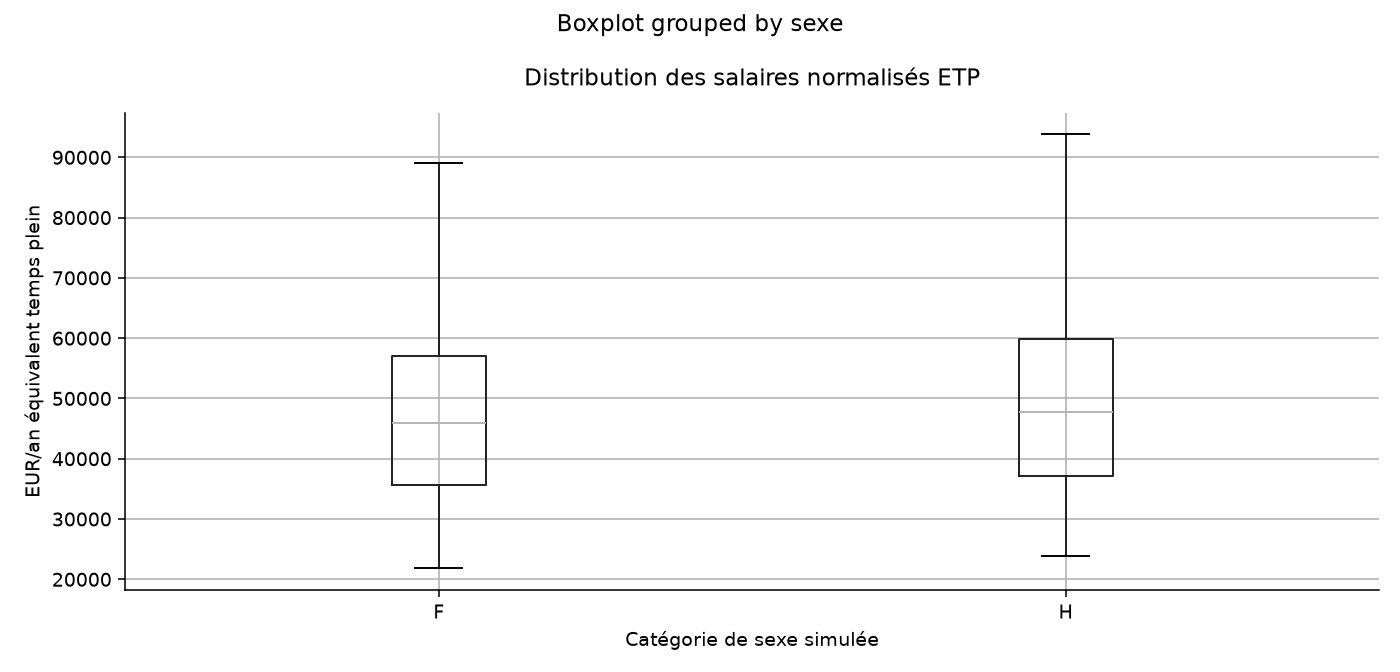

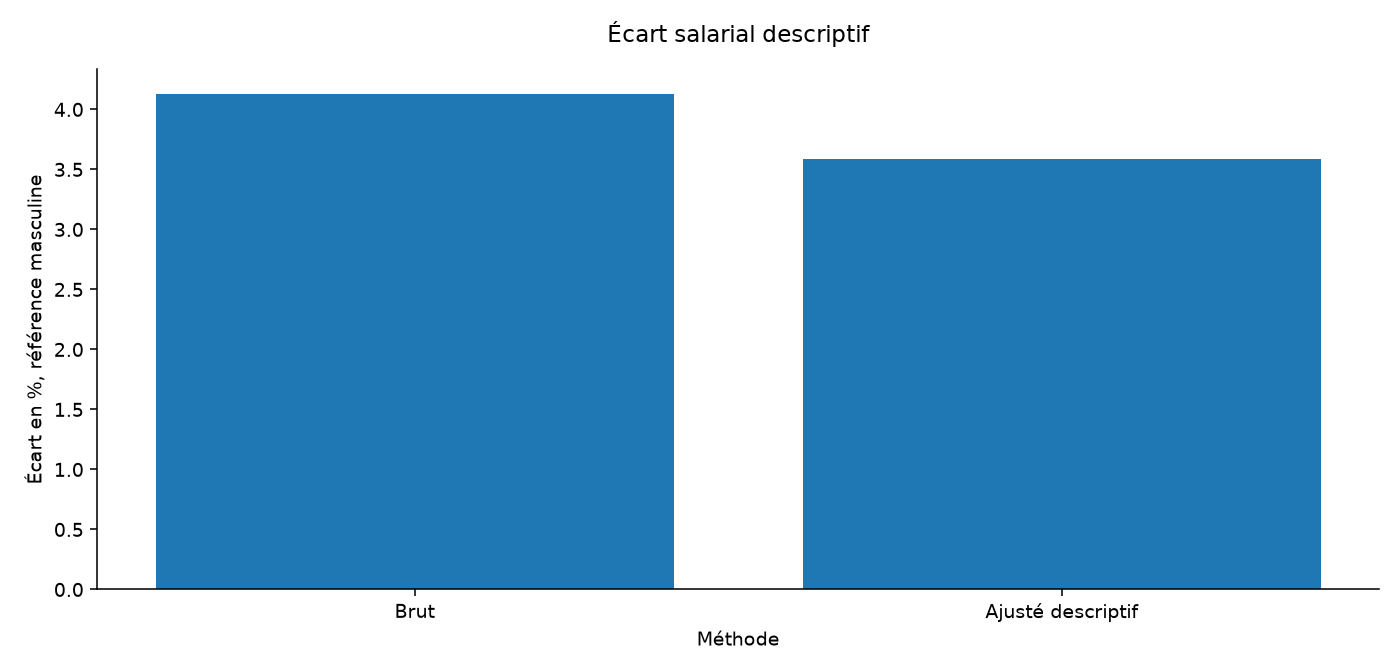

In [21]:
finish('EquiTech — diagnostic de rémunération', 'Distinguer écart brut, composition des postes et association ajustée.', {'effectif': len(v), 'ecart_brut': gap, 'ic95_brut_bas': interval[0], 'ic95_brut_haut': interval[1], 'ecart_ajuste_descriptif': adjusted, 'ecart_ajuste_bas': 1 - np.exp(-ci.iloc[0]), 'ecart_ajuste_haut': 1 - np.exp(-ci.iloc[1]), 'r2': model.rsquared, 'groupes_masques': int(hidden.sum())}, {'indicateurs_agreges': agg, 'coefficients_modele': coef}, [f'Écart brut ETP : {100 * gap:.2f} % ; IC bootstrap [{100 * interval[0]:.2f} ; {100 * interval[1]:.2f}] %.', f'Écart ajusté descriptif : {100 * adjusted:.2f} %, erreurs robustes HC3.'], ['Examiner les distributions par métier et niveau avant interprétation.', 'Appliquer contrôle d’accès et diffusion agrégée sur de vraies données.'], ['Données fictives ; catégories de sexe simplifiées.', 'Ce diagnostic n’est ni l’index légal français ni une preuve de discrimination.', 'Pseudonymisation et seuil de 10 ne garantissent pas anonymisation ou conformité RGPD ; données individuelles publiables ici uniquement car synthétiques.', 'Workflow KNIME à reconstruire ; référence exécutée en Python.'])

In [22]:
import pandas as pd, numpy as np

## Analyse approfondie et interprétation

Les calculs suivants relisent les CSV produits par ce notebook et les confrontent aux hypothèses métier. Les tableaux affichés sont limités à trente lignes ; les exports CSV restent complets.

In [23]:
r = Restitution()

In [24]:
m = r.m

In [25]:
n = r.number

In [26]:
p = r.pct

In [27]:
e = r.money

In [28]:
d = r.read('data/processed/rh_normalise.csv')

In [29]:
a = r.read('analysis/indicateurs_agreges.csv')

In [30]:
coef = r.read('analysis/coefficients_modele.csv')

In [31]:
sexes = d.groupby('sexe').agg(effectif=('salarie_id', 'size'), salaire_verse_moyen=('salaire_annuel_verse', 'mean'), salaire_etp_moyen=('salaire_etp', 'mean'), salaire_etp_median=('salaire_etp', 'median'), quotite_moyenne=('quotite', 'mean')).reset_index()

In [32]:
by = d.groupby(['niveau', 'sexe']).agg(effectif=('salarie_id', 'size'), moyenne_etp=('salaire_etp', 'mean'), mediane_etp=('salaire_etp', 'median')).reset_index()

In [33]:
weights = d.niveau.value_counts(normalize=True)

In [34]:
pivot = by.pivot(index='niveau', columns='sexe', values='moyenne_etp')

In [35]:
reweighted = pivot.mul(weights, axis=0).sum()

In [36]:
gap_level = 1 - reweighted.F / reweighted.H

In [37]:
counts = d.groupby(['niveau', 'sexe']).size().unstack()

In [38]:
shares = counts.div(counts.sum(axis=0), axis=1).reset_index()

In [39]:
small = a[a.masque_seuil_10]

In [40]:
full_means = d.groupby('sexe').salaire_annuel_verse.mean()

In [41]:
raw_gap = 1 - full_means.F / full_means.H

In [42]:
summary = pd.DataFrame({'mesure': ['Écart sur salaire versé', 'Écart brut normalisé ETP', 'Écart standardisé par niveau', 'Écart ajusté, régression log'], 'ecart': [raw_gap, m['ecart_brut'], gap_level, m['ecart_ajuste_descriptif']]})

In [43]:
selected = coef[coef.terme.str.contains('sexe|niveau|anciennete|age')].copy()

In [44]:
selected['facteur_multiplicatif'] = np.exp(selected.coefficient)

In [45]:
r.resume = [f"EquiTech retient {n(m['effectif'], 0)} salariés fictifs après contrôle des identifiants, des quotités et des rémunérations. Les quotités sont normalisées avant toute comparaison.", f"L’écart brut sur salaire ETP est {p(m['ecart_brut'], 2)}, avec intervalle bootstrap [{p(m['ic95_brut_bas'], 2)} ; {p(m['ic95_brut_haut'], 2)}].", f"Après ajustement descriptif des covariables, l’écart est {p(m['ecart_ajuste_descriptif'], 2)}, avec intervalle robuste [{p(m['ecart_ajuste_bas'], 2)} ; {p(m['ecart_ajuste_haut'], 2)}]. Ce n’est ni une preuve de discrimination ni un index légal.", f"{m['groupes_masques']} cellules sous le seuil de dix salariés sont masquées dans la restitution agrégée ; cette règle seule ne garantit pas l’anonymat."]

In [46]:
r.section('4. Rendre les rémunérations comparables', ['Le salaire versé correspond au temps contractuel. Une personne à 50 % et une personne à temps plein ne sont pas directement comparables sur ce montant annuel. Le salaire ETP est défini par salaire_annuel_verse / quotite ; une quotité nulle ou hors intervalle rend le calcul invalide.', f"L’écart calculé directement sur le salaire versé vaut {p(raw_gap, 2)} ; après normalisation ETP, il vaut {p(m['ecart_brut'], 2)}. Cette différence illustre l’importance de la définition, sans fournir une explication causale de la répartition des temps partiels.", 'Les quantités sont vérifiées avant division et les anciennetés simulées sont bornées par l’âge d’entrée plausible dans l’emploi. Le jeu ne contient pas de nom, d’adresse ou de vrai salarié. Les identifiants EMP sont fictifs et ne constituent pas une démonstration d’anonymisation sur des personnes réelles.', 'La moyenne et la médiane décrivent deux aspects différents : la moyenne est sensible aux rémunérations élevées, tandis que la médiane situe le centre de la distribution. L’ETP normalise une quantité de travail contractuelle, pas la fonction, la performance ou l’ensemble des composantes de rémunération.'], [('Rémunérations et quotités par sexe simulé', sexes)])

## 4. Rendre les rémunérations comparables

Le salaire versé correspond au temps contractuel. Une personne à 50 % et une personne à temps plein ne sont pas directement comparables sur ce montant annuel. Le salaire ETP est défini par salaire_annuel_verse / quotite ; une quotité nulle ou hors intervalle rend le calcul invalide.

L’écart calculé directement sur le salaire versé vaut 4,55 % ; après normalisation ETP, il vaut 4,13 %. Cette différence illustre l’importance de la définition, sans fournir une explication causale de la répartition des temps partiels.

Les quantités sont vérifiées avant division et les anciennetés simulées sont bornées par l’âge d’entrée plausible dans l’emploi. Le jeu ne contient pas de nom, d’adresse ou de vrai salarié. Les identifiants EMP sont fictifs et ne constituent pas une démonstration d’anonymisation sur des personnes réelles.

La moyenne et la médiane décrivent deux aspects différents : la moyenne est sensible aux rémunérations élevées, tandis que la médiane situe le centre de la distribution. L’ETP normalise une quantité de travail contractuelle, pas la fonction, la performance ou l’ensemble des composantes de rémunération.

### Rémunérations et quotités par sexe simulé

  sexe  effectif  salaire_verse_moyen  salaire_etp_moyen  salaire_etp_median  \
0    F      6113         44463.671148       48102.664072            45931.41   
1    H      5857         46581.246889       50174.028698            47736.22   

   quotite_moyenne  
0         0.924522  
1         0.928667  

In [47]:
r.section('5. Lire l’écart brut et son incertitude', [f"L’écart retenu est 1 − moyenne_F / moyenne_H, avec H comme référence au dénominateur. Il vaut {p(m['ecart_brut'], 2)}. Une valeur positive signifie une moyenne F inférieure dans cette convention ; inverser le dénominateur ne produit pas le même pourcentage en valeur absolue.", f"Le bootstrap rééchantillonne séparément les deux groupes 500 fois. Les quantiles 2,5 % et 97,5 % donnent [{p(m['ic95_brut_bas'], 2)} ; {p(m['ic95_brut_haut'], 2)}]. Cet intervalle décrit la variabilité de cette procédure sur la simulation, pas l’ensemble des erreurs de mesure ou de sélection d’un cas réel.", 'La répartition par niveau de poste est présentée ci-dessous. Un écart agrégé peut refléter simultanément la composition des postes et des différences au sein d’un même niveau. Les deux questions ont un intérêt métier distinct : accès aux fonctions et rémunération à caractéristiques observées comparables.', 'Le bootstrap suppose ici des salariés indépendants. Un cas réel avec équipes, établissements ou politiques salariales partagées pourrait demander un plan de rééchantillonnage groupé. L’intervalle ne doit donc pas être présenté comme une garantie de précision universelle.'], [('Composition des niveaux, parts par groupe', shares), ('Salaires par niveau et groupe', by)])

## 5. Lire l’écart brut et son incertitude

L’écart retenu est 1 − moyenne_F / moyenne_H, avec H comme référence au dénominateur. Il vaut 4,13 %. Une valeur positive signifie une moyenne F inférieure dans cette convention ; inverser le dénominateur ne produit pas le même pourcentage en valeur absolue.

Le bootstrap rééchantillonne séparément les deux groupes 500 fois. Les quantiles 2,5 % et 97,5 % donnent [3,07 % ; 5,19 %]. Cet intervalle décrit la variabilité de cette procédure sur la simulation, pas l’ensemble des erreurs de mesure ou de sélection d’un cas réel.

La répartition par niveau de poste est présentée ci-dessous. Un écart agrégé peut refléter simultanément la composition des postes et des différences au sein d’un même niveau. Les deux questions ont un intérêt métier distinct : accès aux fonctions et rémunération à caractéristiques observées comparables.

Le bootstrap suppose ici des salariés indépendants. Un cas réel avec équipes, établissements ou politiques salariales partagées pourrait demander un plan de rééchantillonnage groupé. L’intervalle ne doit donc pas être présenté comme une garantie de précision universelle.

### Composition des niveaux, parts par groupe

sexe    niveau         F         H
0     Confirme  0.349746  0.342496
1       Junior  0.304760  0.300837
2      Manager  0.097497  0.099710
3       Senior  0.247996  0.256957

### Salaires par niveau et groupe

     niveau sexe  effectif   moyenne_etp  mediane_etp
0  Confirme    F      2138  45539.256448    45170.380
1  Confirme    H      2006  47159.360482    46788.100
2    Junior    F      1863  32564.796632    32278.440
3    Junior    H      1762  33722.434434    33376.165
4   Manager    F       596  78015.905482    77418.650
5   Manager    H       584  80691.516383    79837.695
6    Senior    F      1516  59052.084032    58410.300
7    Senior    H      1505  61611.185327    61147.730

In [48]:
r.section('6. Comparer standardisation et régression ajustée', [f'Une standardisation simple applique à chaque groupe les mêmes poids de niveaux, ceux de la population totale. L’écart obtenu est {p(gap_level, 2)}. Il contrôle uniquement la composition des niveaux ; il ne remplace pas un ajustement sur toutes les caractéristiques observées.', 'La régression utilise log(salaire_etp) avec sexe, niveau, métier, site, ancienneté et âge. Les catégories sont encodées avec une référence et les erreurs-types sont robustes HC3. La comparaison ajustée est une association conditionnelle au modèle spécifié, sans mécanisme causal identifié.', f"Le coefficient masculin est converti en écart de convention F versus H par 1 − exp(−coefficient_H), soit {p(m['ecart_ajuste_descriptif'], 2)}. Utiliser directement le coefficient log comme pourcentage serait une approximation ; l’exponentiation et le sens de comparaison sont donc explicités.", f"Le R² est {n(m['r2'], 3)}. Une grande part du salaire a été programmée à partir des niveaux et de l’ancienneté ; ce score élevé est attendu dans une simulation. Il ne valide pas une théorie de détermination des salaires ni l’absence de variables omises.", 'Écart brut, standardisé et ajusté ne s’annulent pas nécessairement. Ils répondent à des périmètres de comparaison différents. Les primes, parcours, responsabilités détaillées, temps de présence et trajectoires de promotion restent absents.'], [('Quatre lectures de l’écart', summary), ('Coefficients sélectionnés et intervalles log', selected[['terme', 'coefficient', 'ic95_bas', 'ic95_haut', 'facteur_multiplicatif']])])

## 6. Comparer standardisation et régression ajustée

Une standardisation simple applique à chaque groupe les mêmes poids de niveaux, ceux de la population totale. L’écart obtenu est 3,64 %. Il contrôle uniquement la composition des niveaux ; il ne remplace pas un ajustement sur toutes les caractéristiques observées.

La régression utilise log(salaire_etp) avec sexe, niveau, métier, site, ancienneté et âge. Les catégories sont encodées avec une référence et les erreurs-types sont robustes HC3. La comparaison ajustée est une association conditionnelle au modèle spécifié, sans mécanisme causal identifié.

Le coefficient masculin est converti en écart de convention F versus H par 1 − exp(−coefficient_H), soit 3,59 %. Utiliser directement le coefficient log comme pourcentage serait une approximation ; l’exponentiation et le sens de comparaison sont donc explicités.

Le R² est 0,897. Une grande part du salaire a été programmée à partir des niveaux et de l’ancienneté ; ce score élevé est attendu dans une simulation. Il ne valide pas une théorie de détermination des salaires ni l’absence de variables omises.

Écart brut, standardisé et ajusté ne s’annulent pas nécessairement. Ils répondent à des périmètres de comparaison différents. Les primes, parcours, responsabilités détaillées, temps de présence et trajectoires de promotion restent absents.

### Quatre lectures de l’écart

                         mesure     ecart
0       Écart sur salaire versé  0.045460
1      Écart brut normalisé ETP  0.041284
2  Écart standardisé par niveau  0.036390
3  Écart ajusté, régression log  0.035886

### Coefficients sélectionnés et intervalles log

                   terme  coefficient  ic95_bas  ic95_haut  \
1           C(sexe)[T.H]     0.036546  0.033009   0.040084   
2    C(niveau)[T.Junior]    -0.335099 -0.339495  -0.330703   
3   C(niveau)[T.Manager]     0.539785  0.533364   0.546207   
4    C(niveau)[T.Senior]     0.266335  0.261716   0.270954   
13            anciennete     0.009879  0.009605   0.010153   
14                   age     0.000091 -0.000060   0.000241   

    facteur_multiplicatif  
1                1.037222  
2                0.715267  
3                1.715639  
4                1.305172  
13               1.009928  
14               1.000091  

In [49]:
r.section('7. Diffuser des agrégats sans surestimer la protection', [f'Les croisements site × métier × niveau × sexe produisent {len(a)} cellules ; {len(small)} sont sous dix salariés et n’affichent ni effectif ni rémunération. Les mesures correspondantes restent non observées dans l’export public, plutôt que remplacées par zéro.', 'Masquer une seule petite cellule peut être insuffisant si un total de ligne ou une autre vue permet de la retrouver par soustraction. Une stratégie réelle demanderait des contrôles de complémentarité entre tableaux et, selon le contexte, une suppression secondaire ou une agrégation plus large.', 'Le rapport ne conclut pas à une conformité RGPD. Les principes de minimisation, contrôle d’accès et durée de conservation doivent être appliqués dans un contexte défini et validé. La publication des lignes individuelles est acceptable dans cet exercice uniquement parce qu’elles sont intégralement fabriquées.', 'La restitution distingue donc un diagnostic statistique de démonstration, une procédure de gouvernance à construire et les calculs réglementaires éventuels. Le simple fait d’utiliser un outil de traitement ne résout aucune de ces exigences à lui seul.'], [('Cellules protégées, valeurs masquées', small)])

## 7. Diffuser des agrégats sans surestimer la protection

Les croisements site × métier × niveau × sexe produisent 165 cellules ; 5 sont sous dix salariés et n’affichent ni effectif ni rémunération. Les mesures correspondantes restent non observées dans l’export public, plutôt que remplacées par zéro.

Masquer une seule petite cellule peut être insuffisant si un total de ligne ou une autre vue permet de la retrouver par soustraction. Une stratégie réelle demanderait des contrôles de complémentarité entre tableaux et, selon le contexte, une suppression secondaire ou une agrégation plus large.

Le rapport ne conclut pas à une conformité RGPD. Les principes de minimisation, contrôle d’accès et durée de conservation doivent être appliqués dans un contexte défini et validé. La publication des lignes individuelles est acceptable dans cet exercice uniquement parce qu’elles sont intégralement fabriquées.

La restitution distingue donc un diagnostic statistique de démonstration, une procédure de gouvernance à construire et les calculs réglementaires éventuels. Le simple fait d’utiliser un outil de traitement ne résout aucune de ces exigences à lui seul.

### Cellules protégées, valeurs masquées

          site      metier    niveau sexe  effectif  salaire_etp_moyen  \
40  Micro_site  Commercial   Manager    H       NaN                NaN   
41  Micro_site     Finance  Confirme    F       NaN                NaN   
42  Micro_site  Operations  Confirme    F       NaN                NaN   
43  Micro_site  Operations  Confirme    H       NaN                NaN   
44  Micro_site     Support    Junior    F       NaN                NaN   

    salaire_etp_median  masque_seuil_10  
40                 NaN             True  
41                 NaN             True  
42                 NaN             True  
43                 NaN             True  
44                 NaN             True  

In [50]:
r.section('8. Décider des vérifications complémentaires', ['Le bon usage des résultats est de définir un audit complémentaire : vérifier la comparabilité des fonctions, analyser les trajectoires d’accès aux niveaux, intégrer les composantes de rémunération et documenter le périmètre temporel.', 'Aucune action individuelle n’est recommandée à partir d’un coefficient global. Il faut distinguer une différence moyenne observée d’une situation individuelle, puis vérifier les données et les règles de comparaison avant toute décision.', 'L’approfondissement prioritaire est la qualité de la description des postes et des trajectoires. Des résultats plus précis sur un modèle mal spécifié ne remplaceraient pas ces informations. La lecture doit rester explicative et prudente.'])

## 8. Décider des vérifications complémentaires

Le bon usage des résultats est de définir un audit complémentaire : vérifier la comparabilité des fonctions, analyser les trajectoires d’accès aux niveaux, intégrer les composantes de rémunération et documenter le périmètre temporel.

Aucune action individuelle n’est recommandée à partir d’un coefficient global. Il faut distinguer une différence moyenne observée d’une situation individuelle, puis vérifier les données et les règles de comparaison avant toute décision.

L’approfondissement prioritaire est la qualité de la description des postes et des trajectoires. Des résultats plus précis sur un modèle mal spécifié ne remplaceraient pas ces informations. La lecture doit rester explicative et prudente.

In [51]:
r.actions = [('P1', 'Écart ETP brut : ' + p(m['ecart_brut'], 2), 'Valider les définitions de salaire et de temps contractuel', 'Périmètre et composantes comparables documentés'), ('P1', 'Écart ajusté : ' + p(m['ecart_ajuste_descriptif'], 2), 'Examiner covariables et parcours manquants', 'Association présentée sans causalité ni index légal'), ('P1', str(len(small)) + ' petites cellules', 'Tester les divulgations par totaux et croisements', 'Aucune reconstruction de groupes masqués dans les vues diffusées'), ('P2', 'Différences de composition des postes', 'Étudier les trajectoires et promotions dans un cas réel', 'Résultats agrégés au bon périmètre et gouvernance validée')]

In [52]:
display(Markdown('## Synthèse argumentée\n\n' + '\n\n'.join(r.resume)))
if r.actions:
    display(pd.DataFrame(r.actions))

## Synthèse argumentée

EquiTech retient 11 970 salariés fictifs après contrôle des identifiants, des quotités et des rémunérations. Les quotités sont normalisées avant toute comparaison.

L’écart brut sur salaire ETP est 4,13 %, avec intervalle bootstrap [3,07 % ; 5,19 %].

Après ajustement descriptif des covariables, l’écart est 3,59 %, avec intervalle robuste [3,25 % ; 3,93 %]. Ce n’est ni une preuve de discrimination ni un index légal.

5 cellules sous le seuil de dix salariés sont masquées dans la restitution agrégée ; cette règle seule ne garantit pas l’anonymat.

    0                                      1  \
0  P1                Écart ETP brut : 4,13 %   
1  P1                  Écart ajusté : 3,59 %   
2  P1                     5 petites cellules   
3  P2  Différences de composition des postes   

                                                   2  \
0  Valider les définitions de salaire et de temps...   
1         Examiner covariables et parcours manquants   
2  Tester les divulgations par totaux et croisements   
3  Étudier les trajectoires et promotions dans un...   

                                                   3  
0    Périmètre et composantes comparables documentés  
1  Association présentée sans causalité ni index ...  
2  Aucune reconstruction de groupes masqués dans ...  
3  Résultats agrégés au bon périmètre et gouverna...  

## Présentation PowerPoint

Cette cellule régénère une présentation modifiable à partir des résultats calculés. Les graphiques sont des images ; titres, textes et recommandations restent éditables dans PowerPoint.

In [53]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
